# Top-Down vs Bottom-Up Forecast Reconciliation: FMCG Demand Planning
Hierarchy: Total > State > Store > Item (M5 Walmart FOODS_3 as an FMCG stand-in).
Everything is built from scratch with numpy, pandas and statsmodels (no extra installs).

### Cell 1: settings and data

In [1]:
import pandas as pd, numpy as np, warnings, time
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
from statsmodels.tsa.holtwinters import ExponentialSmoothing

N_ITEMS = 50       # items sampled from FOODS_3 (raise to 100 if it runs fast)
H = 6              # forecast horizon (months)
N_WINDOWS = 3      # rolling-origin test windows
SEASON = 12        # monthly seasonality

sales = pd.read_csv('sales_train_evaluation.csv')
cal = pd.read_csv('calendar.csv', parse_dates=['date'])

sales = sales[sales.dept_id == 'FOODS_3']
items = sales.item_id.drop_duplicates().sample(N_ITEMS, random_state=42)
sales = sales[sales.item_id.isin(items)].reset_index(drop=True)

dcols = [c for c in sales.columns if c.startswith('d_')]
cal = cal.set_index('d').loc[dcols]
month = cal['date'].dt.to_period('M').dt.to_timestamp()

monthly = sales[dcols].T.groupby(month).sum().T
monthly = monthly.iloc[:, 1:-1]                 # drop first and last partial months
months = monthly.columns
B = monthly.values.astype(float)                # bottom level: (store-item series) x months
meta = sales[['state_id', 'store_id', 'item_id']]
m, T = B.shape
print('bottom series:', m, '| months:', T, '|', months[0].date(), 'to', months[-1].date())

bottom series: 500 | months: 63 | 2011-02-01 to 2016-04-01


### Cell 2: build the hierarchy (summing matrix S)

In [2]:
rows = [np.ones((1, m))]; names = ['Total']; level = ['Total']
for lvl, col in (('State', 'state_id'), ('Store', 'store_id')):
    dmy = pd.get_dummies(meta[col]).astype(float)
    rows.append(dmy.T.values); names += list(dmy.columns); level += [lvl] * dmy.shape[1]
rows.append(np.eye(m))
names += list(meta['item_id'] + '|' + meta['store_id']); level += ['Item'] * m
S = np.vstack(rows); level = np.array(level); names = np.array(names)
n = S.shape[0]
Y = S @ B                                       # every series in the hierarchy
print('total series in hierarchy:', n, {l: int((level == l).sum()) for l in ['Total', 'State', 'Store', 'Item']})

store_rows = np.where(level == 'Store')[0]
item_store = S[store_rows].argmax(axis=0)       # for each bottom series, which store it belongs to
LEVELS = ['Total', 'State', 'Store', 'Item']

total series in hierarchy: 514 {'Total': 1, 'State': 3, 'Store': 10, 'Item': 500}


### Cell 3: base forecasts and reconciliation methods

In [3]:
def base_forecast(y, h):
    """Holt-Winters (additive seasonal). Falls back to seasonal naive if it fails."""
    try:
        if np.count_nonzero(y) < 4:
            raise ValueError
        fit = ExponentialSmoothing(y, trend=None, seasonal='add', seasonal_periods=SEASON,
                                   initialization_method='estimated').fit()
        fc, res = np.asarray(fit.forecast(h)), y - np.asarray(fit.fittedvalues)
    except Exception:
        fc = np.resize(y[-SEASON:], h)
        res = np.concatenate([np.zeros(SEASON), y[SEASON:] - y[:-SEASON]])
    return np.maximum(fc, 0), res

def snaive(y, h):
    return np.resize(y[-SEASON:], h)

def shrink_cov(E):
    """MinT-shrink covariance of base-forecast residuals (Schafer-Strimmer shrinkage)."""
    k, Tn = E.shape
    E = E - E.mean(1, keepdims=True)
    sd = E.std(1, ddof=1)
    sd = np.maximum(sd, 0.01 * np.median(sd[sd > 0]))
    X = E / sd[:, None]
    R = X @ X.T / (Tn - 1)
    X2 = X ** 2
    var_r = Tn / (Tn - 1) ** 3 * (X2 @ X2.T - (X @ X.T) ** 2 / Tn)
    off = ~np.eye(k, dtype=bool)
    lam = np.clip(var_r[off].sum() / (R[off] ** 2).sum(), 0, 1)
    Rs = lam * np.eye(k) + (1 - lam) * R
    return sd[:, None] * Rs * sd[None, :], lam

def G_matrix(Winv_diag=None, W=None):
    """Projection G = (S' W^-1 S)^-1 S' W^-1 (W=None and Winv_diag=None gives OLS)."""
    if W is not None:
        WiS = np.linalg.solve(W, S)
        return np.linalg.solve(S.T @ WiS, WiS.T)
    wi = np.ones(n) if Winv_diag is None else Winv_diag
    return np.linalg.solve(S.T @ (wi[:, None] * S), (S * wi[:, None]).T)

G_ols = G_matrix()
G_wls = G_matrix(Winv_diag=1.0 / S.sum(1))

def reconcile_all(yhat, Btr, resid):
    """yhat: n x H base forecasts. Btr: bottom-level training data. Returns dict method -> n x H."""
    Ytr_tot = Btr.sum(0)
    out = {'Base (unreconciled)': yhat}
    out['Bottom-up'] = S @ yhat[-m:]
    p_avg = (Btr / Ytr_tot).mean(1)                       # average historical proportions
    p_prop = Btr.mean(1) / Ytr_tot.mean()                 # proportion of historical averages
    out['Top-down (avg proportions)'] = S @ (p_avg[:, None] * yhat[0][None, :])
    out['Top-down (prop. of averages)'] = S @ (p_prop[:, None] * yhat[0][None, :])
    st_tr = np.vstack([Btr[item_store == k].sum(0) for k in range(len(store_rows))])
    p_mid = np.array([(Btr[i] / np.maximum(st_tr[item_store[i]], 1e-9)).mean() for i in range(m)])
    out['Middle-out (Store)'] = S @ (p_mid[:, None] * yhat[store_rows][item_store])
    out['OLS reconciliation'] = S @ (G_ols @ yhat)
    out['WLS reconciliation'] = S @ (G_wls @ yhat)
    W, lam = shrink_cov(resid)
    out['MinT-shrink'] = S @ (G_matrix(W=W) @ yhat)
    return out, lam

### Cell 4: rolling-origin evaluation (runs the whole experiment)

In [4]:
records, gap_records, store_plot = [], [], {}
t0 = time.time()
for w in range(N_WINDOWS):
    tr_end = T - H * (w + 1)
    Ytr, Yte = Y[:, :tr_end], Y[:, tr_end:tr_end + H]
    Btr = B[:, :tr_end]
    yhat = np.zeros((n, H)); resid = np.zeros((n, tr_end))
    for i in range(n):
        yhat[i], resid[i] = base_forecast(Ytr[i], H)
    methods, lam = reconcile_all(yhat, Btr, resid)
    methods['Seasonal naive'] = np.vstack([snaive(Ytr[i], H) for i in range(n)])
    scale = np.abs(np.diff(Ytr, axis=1)).mean(1)

    # how badly do the unreconciled forecasts disagree?
    gap_total = np.abs(yhat[0] - yhat[-m:].sum(0)).mean() / yhat[0].mean()
    gap_state = np.mean([np.abs(yhat[j] - yhat[store_rows][S[store_rows][:, S[j] == 1].sum(1) > 0].sum(0)).mean() / max(yhat[j].mean(), 1e-9)
                         for j in np.where(level == 'State')[0]])
    gap_records.append({'window': w, 'Total vs sum of items': gap_total, 'State vs sum of stores': gap_state})

    for meth, fc in methods.items():
        mae = np.abs(Yte - fc).mean(1)
        mase = np.where(scale > 0, mae / np.where(scale > 0, scale, 1), np.nan)
        bias = (fc - Yte).mean(1)
        for i in range(n):
            records.append((w, meth, i, level[i], mae[i], mase[i], bias[i]))
    if w == 0:
        store_plot = {'actual': Yte[0], 'hist': Ytr[0], 'methods': {k: v[0] for k, v in methods.items()}, 'tr_end': tr_end}
    print(f'window {w + 1}/{N_WINDOWS} done | MinT shrinkage lambda={lam:.2f} | {time.time() - t0:.0f}s elapsed')

R = pd.DataFrame(records, columns=['window', 'method', 'series', 'level', 'MAE', 'MASE', 'bias'])
gaps = pd.DataFrame(gap_records)
R.to_csv('all_results.csv', index=False)

window 1/3 done | MinT shrinkage lambda=0.69 | 74s elapsed
window 2/3 done | MinT shrinkage lambda=0.68 | 140s elapsed
window 3/3 done | MinT shrinkage lambda=0.67 | 212s elapsed


### Cell 5: results and insights


=== TABLE 1: mean MASE by method and level (lower is better) ===
level                         Total  State  Store   Item  Average
method                                                           
Seasonal naive                2.255  2.040  2.147  4.373    2.704
Base (unreconciled)           1.670  1.812  1.802  3.592    2.219
Bottom-up                     1.754  1.829  1.821  3.592    2.249
Top-down (avg proportions)    1.670  1.955  2.164  4.787    2.644
Top-down (prop. of averages)  1.670  1.906  2.068  4.582    2.556
Middle-out (Store)            1.612  1.780  1.802  4.811    2.501
OLS reconciliation            1.663  1.827  1.824  3.714    2.257
WLS reconciliation            1.666  1.798  1.802  3.624    2.222
MinT-shrink                   1.706  1.823  1.818  3.593    2.235

=== TABLE 2: % improvement over unreconciled base forecasts (positive = better) ===
level                         Total  State  Store  Item  Average
method                                                    

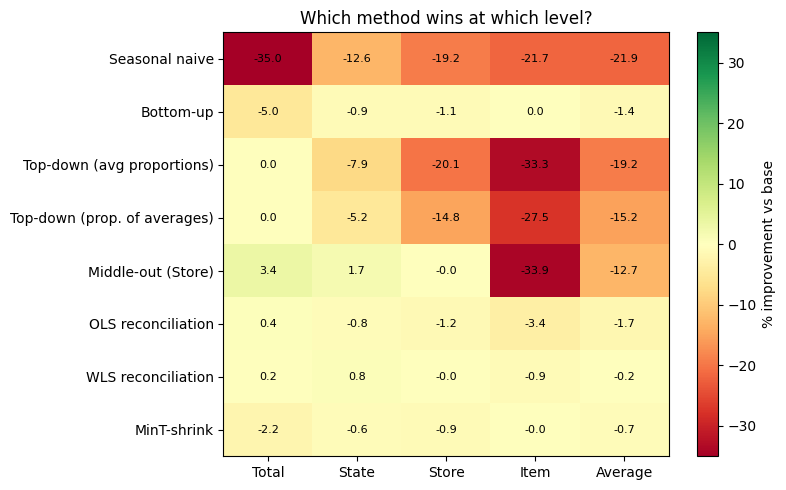

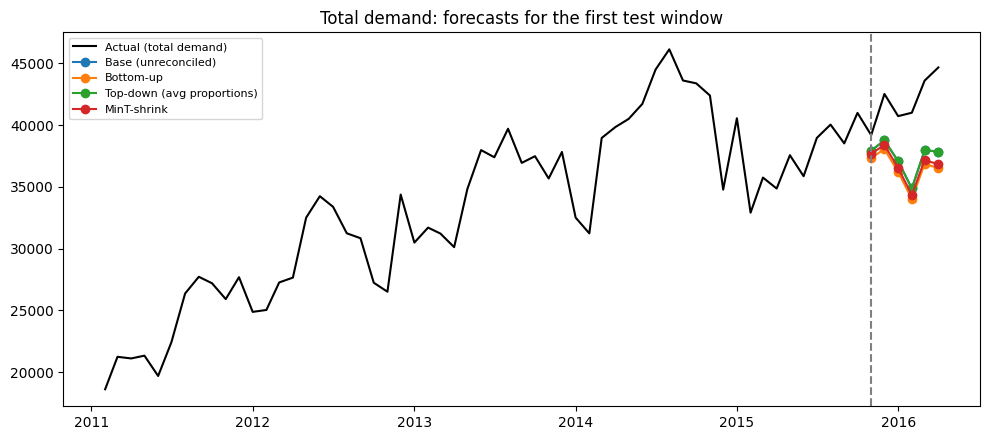

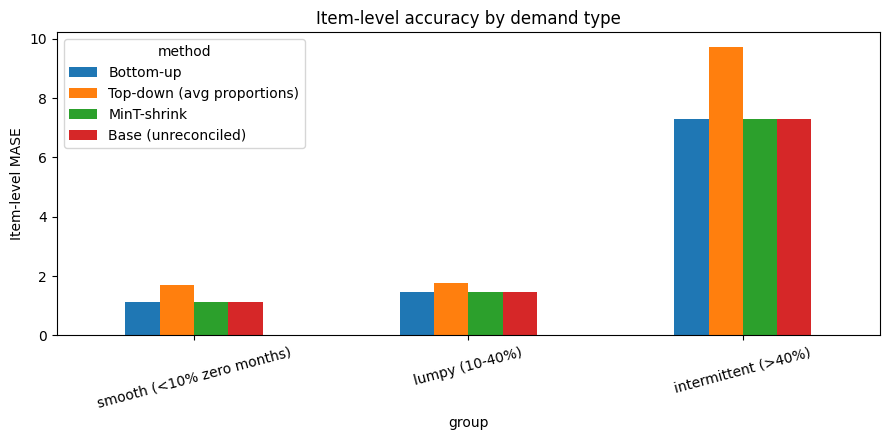

In [5]:
order = ['Seasonal naive', 'Base (unreconciled)', 'Bottom-up', 'Top-down (avg proportions)',
         'Top-down (prop. of averages)', 'Middle-out (Store)', 'OLS reconciliation',
         'WLS reconciliation', 'MinT-shrink']
mase = R.groupby(['method', 'level'])['MASE'].mean().unstack('level')[LEVELS].loc[order]
mase['Average']= mase.mean(1)
print('\n=== TABLE 1: mean MASE by method and level (lower is better) ===')
print(mase.round(3))
mase.round(4).to_csv('table1_mase.csv')

base = mase.loc['Base (unreconciled)']
gain = ((base - mase) / base * 100).drop(['Base (unreconciled)'])
print('\n=== TABLE 2: % improvement over unreconciled base forecasts (positive = better) ===')
print(gain.round(1))
gain.round(2).to_csv('table2_gain_pct.csv')

recon = order[2:]
best = mase.loc[recon, LEVELS].idxmin()
print('\n=== Best reconciliation method per level ===')
print(best.to_string())

# win rate: among series whose forecast actually changed, how often is the method better than base?
from scipy.stats import wilcoxon
piv = R.pivot_table(index=['window', 'series'], columns='method', values='MASE')
rows_w = []
for k in recon:
    d = (piv['Base (unreconciled)'] - piv[k]).dropna()
    d = d[d.abs() > 1e-9]
    try:
        p = wilcoxon(d).pvalue
    except Exception:
        p = np.nan
    rows_w.append({'method': k, 'series changed': len(d), 'win rate %': round((d > 0).mean() * 100, 1) if len(d) else np.nan,
                   'p-value (Wilcoxon)': round(p, 4)})
win = pd.DataFrame(rows_w).set_index('method')
print('\n=== Win rate vs base (only series where the forecast changed) + significance ===')
print(win)
win.to_csv('table4_winrate.csv')

# coherence gap of base forecasts
print('\n=== How much do unreconciled forecasts disagree? (avg gap as % of the level total) ===')
print((gaps[['Total vs sum of items', 'State vs sum of stores']].mean() * 100).round(1).to_string())

# intermittency: items grouped by share of zero-sales months
zero_share = pd.Series((B == 0).mean(1), index=range(n - m, n))
grp = pd.cut(zero_share, [-0.01, 0.1, 0.4, 1.0], labels=['smooth (<10% zero months)', 'lumpy (10-40%)', 'intermittent (>40%)'])
it = R[R.level == 'Item'].copy(); it['group'] = it['series'].map(grp)
inter = it.groupby(['method', 'group'])['MASE'].mean().unstack('group').loc[recon + ['Seasonal naive', 'Base (unreconciled)']]
print('\n=== Item-level MASE by demand type ===')
print(inter.round(3))
print('items per group:', grp.value_counts().to_dict())
inter.round(4).to_csv('table3_intermittency.csv')

# bias: do some methods over- or under-forecast?
bias = R[R.level == 'Total'].groupby('method')['bias'].mean().loc[order]
print('\n=== Bias at Total level (units/month; positive = over-forecast) ===')
print(bias.round(1).to_string())

# automatic insight sentences for the report
L = []
for lv in LEVELS:
    L.append(f"At the {lv} level the best reconciliation method was {best[lv]} (MASE {mase.loc[best[lv], lv]:.3f}) "
             f"versus {base[lv]:.3f} for the unreconciled base forecast ({gain.loc[best[lv], lv]:+.1f}%).")
bo = mase.loc[recon, 'Average'].idxmin()
L.append(f"Averaged over all four levels, {bo} was best (MASE {mase.loc[bo, 'Average']:.3f}).")
L.append(f"Unreconciled forecasts disagreed with each other by about {gaps['Total vs sum of items'].mean() * 100:.1f}% at the Total level "
         f"(Total forecast vs sum of item forecasts).")
w_best = win['win rate %'].idxmax(); L.append(f"{w_best} improved on the base forecast for {win.loc[w_best, 'win rate %']:.0f}% of the series it changed (Wilcoxon p = {win.loc[w_best, 'p-value (Wilcoxon)']}).")
g = inter.columns[-1]
L.append(f"For {g} items, the best method was {inter.loc[recon, g].idxmin()} (MASE {inter.loc[recon, g].min():.3f}) "
         f"versus {inter.loc['Bottom-up', g]:.3f} for bottom-up.")
print('\n=== AUTO INSIGHTS (copy into the report) ===')
for s in L: print('-', s)
open('insights.txt', 'w').write('\n'.join(L))

# charts
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(gain.values, cmap='RdYlGn', aspect='auto', vmin=-max(abs(gain.values.min()), abs(gain.values.max())),
               vmax=max(abs(gain.values.min()), abs(gain.values.max())))
ax.set_xticks(range(len(gain.columns))); ax.set_xticklabels(gain.columns)
ax.set_yticks(range(len(gain.index))); ax.set_yticklabels(gain.index)
for i in range(gain.shape[0]):
    for j in range(gain.shape[1]):
        ax.text(j, i, f'{gain.values[i, j]:.1f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, label='% improvement vs base'); ax.set_title('Which method wins at which level?')
plt.tight_layout(); plt.savefig('fig1_gain_heatmap.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
tr = store_plot['tr_end']
ax.plot(months[:tr + H], np.concatenate([store_plot['hist'], store_plot['actual']]), 'k-', label='Actual (total demand)')
for k in ['Base (unreconciled)', 'Bottom-up', 'Top-down (avg proportions)', 'MinT-shrink']:
    ax.plot(months[tr:tr + H], store_plot['methods'][k], marker='o', label=k)
ax.axvline(months[tr], color='grey', ls='--'); ax.set_title('Total demand: forecasts for the first test window')
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig('fig2_total_forecast.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
inter.loc[['Bottom-up', 'Top-down (avg proportions)', 'MinT-shrink', 'Base (unreconciled)']].T.plot.bar(ax=ax)
ax.set_ylabel('Item-level MASE'); ax.set_title('Item-level accuracy by demand type'); plt.xticks(rotation=15)
plt.tight_layout(); plt.savefig('fig3_intermittency.png', dpi=150); plt.show()